# Classification Evaluation Metrics：分類模型評估指標完整教材

教材專門介紹 Classification（分類模型）的評估指標，包含：

1. Confusion Matrix（混淆矩陣）
2. Accuracy（準確率）
3. Precision（精確率）
4. Recall（召回率）
5. F1-score（F1 分數）
6. ROC Curve / AUC（ROC 曲線與曲線下面積）

這些指標可以用來評估 Logistic Regression、KNN、SVM、Decision Tree、Random Forest 等分類模型。

本次教學的核心問題是：「模型預測正確的比例很高，就代表它是一個好模型嗎？」

答案是：不一定。

例如，一個疾病篩檢模型的 Accuracy 高達 95%，卻可能漏掉大部分真正患病的人。因此，我們不能只看 Accuracy，還需要理解 Precision、Recall、F1-score 與 ROC AUC。

## 為什麼不能只看 Accuracy？

假設有 100 位學生：

```
實際及格：95 人
實際不及格：5 人
```

現在有一個模型，不管輸入什麼學生資料，都預測「及格」。

結果：

```text
95 人預測正確
5 人預測錯誤
```

Accuracy：$\text{Accuracy}=\frac{95}{100}=95\\%$

模型 Accuracy = 95%，但真正不及格者的辨識率為0%。

雖然 Accuracy 高達 95%，但模型完全沒有辨識不及格學生的能力。因此，我們需要根據不同問題選擇不同的評估指標。

## Confusion Matrix（混淆矩陣）

![](./assets/混淆矩陣.png)

### 混淆矩陣實際範例

假設 100 位學生的預測結果如下：

|       | 預測不及格   | 預測及格    |
| ----- | ------- | ------- |
| 實際不及格 | 30 (TN) | 10 (FP) |
| 實際及格  | 15 (FN) | 45 (TP) |

表示：

- 30 位不及格學生被正確辨識。
- 45 位及格學生被正確辨識。
- 10 位不及格學生被錯誤判斷為及格。
- 15 位及格學生被錯誤判斷為不及格。


## Accuracy（準確率）

Accuracy 是最直覺的分類評估指標。描述：「全部資料中，有多少比例預測正確？」

什麼時候適合看 Accuracy？ 當各類別數量比較平均，且不同錯誤的代價差不多時，Accuracy 很適合用來快速比較模型。

$$\boxed{ \text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN} }$$

```python
from sklearn.metrics import accuracy_score

### 計算 Accuracy
accuracy = accuracy_score(y_test, y_pred)
### 顯示結果
print(f"Accuracy：{accuracy:.4f}")
```

## Precision（精確率）

Precision 想回答的是：「模型預測「及格」的人當中，有多少人真的及格？」

$$ \boxed{ \text{Precision}=\frac{TP}{TP+FP} } $$

```python
from sklearn.metrics import precision_score
### 計算 Precision
precision = precision_score(   
	y_test, y_pred,    
	pos_label=1, # 指定 1 為正類別    
	zero_division=0 # 分母為 0 時回傳 0
	)
print(f"Precision：{precision:.4f}")
```

### Precision 適合什麼情境？

例如垃圾郵件偵測，當模型預測某封信是垃圾郵件時，希望真的有很高的機率是垃圾郵件，避免正常信件被錯誤攔截。

這時就很重視 Precision。


## Recall（召回率）

Recall 想回答的是：「所有真正及格的人當中，模型成功找出了多少人？」

$$ \boxed{ \text{Recall}=\frac{TP}{TP+FN} } $$

```python
from sklearn.metrics import recall_score
### 計算 Recall
recall = recall_score(    
	y_test, y_pred,    
	pos_label=1, # 指定 1 為正類別    
	zero_division=0
	)
print(f"Recall：{recall:.4f}")
```

### Recall 適合什麼情境？

例如疾病篩檢，假設 Positive 代表患病。如果模型漏掉真正患病的人，可能造成嚴重後果。因此通常希望提高 Recall，盡量找出真正患病的人。但 Recall 提高後，也可能增加 FP，因此不能只看 Recall 而忽略其他指標。

### Precision 與 Recall 的差異

| 比較   | Precision       | Recall         |
| ---- | --------------- | -------------- |
| 核心問題 | 預測為正的人，有多少真的為正？ | 真正為正的人，有多少被找出？ |
| 主要關注 | FP（誤報）          | FN（漏判）         |
| 分母   | TP + FP         | TP + FN        |
| 常見應用 | 垃圾郵件攔截          | 疾病篩檢           |

## F1-score（F1 分數）

F1-score 是 Precision 與 Recall 的調和平均。當我們希望 Precision 與 Recall 都有不錯的表現時，可以使用 F1-score。

$$ \boxed{ F1=2\times\frac{\text{Precision}\times\text{Recall}} {\text{Precision}+\text{Recall}} } $$

假設：

```
Precision = 0.90
Recall    = 0.50
```

雖然 Precision 很高，但 Recall 偏低，因此 F1-score 會受到影響：

$$ F1=2\times\frac{0.9\times0.5}{0.9+0.5}\approx0.643 $$

這代表模型雖然預測正類別時很精確，但漏掉了不少真正的正類別。

```python
from sklearn.metrics import f1_score
### 計算 F1-score
f1 = f1_score(    
	y_test, y_pred,    
	pos_label=1,    
	zero_division=0)
print(f"F1-score：{f1:.4f}")
```

### F1-score 的重要觀念

| 情況                   | F1-score         |
| -------------------- | ---------------- |
| Precision 高、Recall 高 | 通常高              |
| Precision 高、Recall 低 | 受到低 Recall 拉低    |
| Precision 低、Recall 高 | 受到低 Precision 拉低 |
| Precision 低、Recall 低 | 低                |

F1-score 不考慮 TN，因此不是 Accuracy 的替代品，而是另一種評估角度。

## Classification Threshold（分類門檻）

在介紹 ROC Curve 之前，必須先理解 Threshold。

![](./assets/分類門檻.png)

這個概念非常重要，因為 ROC Curve 就是在觀察不同 Threshold 下的分類表現。

## ROC Curve（接收者操作特徵曲線）

![](./assets/ROC.png)


## AUC（曲線下面積）

![](./assets/AUC.png)

## 實作：使用 Logistic Regression 評估學生是否及格

### 讀取資料集

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 讀取資料集
df = pd.read_csv("./data/classification_metrics_students.csv")

### 查看資料形狀
print(df.shape)

### 查看資料
display(df.head(10))

(1200, 5)


,study_hours,attendance_rate,practice_questions,sleep_hours,passed
0,7.5,76.2,49,8.5,1
1,4.4,75.3,48,5.9,1
2,8.2,90.6,17,3.2,1
3,6.8,84.1,64,4.5,1
4,1.3,46.5,56,9.0,0
5,9.3,47.7,60,6.4,1
6,7.4,78.1,37,5.9,1
7,7.6,71.7,72,9.3,1
8,1.7,59.3,31,8.8,1
9,4.6,68.0,65,7.0,1


### 探索資料 (EDA)

In [2]:
df.info() ### 查看資料型態
display(df.describe()) ### 查看統計資訊
print(df.isnull().sum()) ### 查看缺失值
print(df["passed"].value_counts()) ### 查看類別數量
print(df["passed"].value_counts(normalize=True)) ### 查看類別比例

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   study_hours         1200 non-null   float64
 1   attendance_rate     1200 non-null   float64
 2   practice_questions  1200 non-null   int64  
 3   sleep_hours         1200 non-null   float64
 4   passed              1200 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 47.0 KB


,study_hours,attendance_rate,practice_questions,sleep_hours,passed
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,5.001750,72.264167,40.490000,7.011500,0.596667
std,2.619142,16.022613,23.089554,1.368129,0.490771
min,0.500000,45.000000,0.000000,3.200000,0.000000
25%,2.700000,58.450000,20.000000,6.100000,0.000000
50%,5.000000,71.350000,42.000000,7.000000,1.000000
75%,7.325000,86.600000,60.250000,7.900000,1.000000
max,9.500000,100.000000,80.000000,11.000000,1.000000


study_hours           0
attendance_rate       0
practice_questions    0
sleep_hours           0
passed                0
dtype: int64
passed
1    716
0    484
Name: count, dtype: int64
passed
1    0.596667
0    0.403333
Name: proportion, dtype: float64


### 資料清理

In [3]:
### 移除重複資料
df = df.drop_duplicates().copy()

### 移除 Target 缺失資料
df = df.dropna(subset=["passed"])

### 重設索引
df = df.reset_index(drop=True)

### 查看清理結果
print(df.isnull().sum())

study_hours           0
attendance_rate       0
practice_questions    0
sleep_hours           0
passed                0
dtype: int64


### 選擇 Features 與 Target

In [4]:
### 選擇 Features
X = df[[
    "study_hours",
    "attendance_rate",
    "practice_questions",
    "sleep_hours"
]].copy()

### 選擇 Target
y = df["passed"].astype(int).copy()

### 查看資料形狀
print("Features：", X.shape)
print("Target：", y.shape)

Features： (1200, 4)
Target： (1200,)


### 切分 Train / Test

In [5]:
from sklearn.model_selection import train_test_split

### 切分 Train 80%、Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, # 20% 作為 Test Data
    random_state=42, # 固定隨機種子
    stratify=y # 維持類別比例
)

### 查看切分結果
print("X_train：", X_train.shape)
print("X_test：", X_test.shape)

X_train： (960, 4)
X_test： (240, 4)


### 建立資料前處理 Pipeline

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

### 建立前處理流程
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 使用中位數補值
    ("scaler", StandardScaler()) # 將 Features 標準化
])

### 建立模型

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 Logistic Regression 模型
model = Pipeline([
    ("preprocessor", preprocessor), # 資料前處理
    ("classifier", LogisticRegression(
        max_iter=1000, # 最大迭代次數
        C=1.0, # 正則化強度的反比
        random_state=42 # 固定相關隨機程序
    ))
])

### 訓練模型
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

### 使用模型預測

In [15]:
import pandas as pd

### 預測類別
y_pred = model.predict(X_test)
### 預測正類別 (1) 的機率
y_score = model.predict_proba(X_test)[:, 1]

### 整理預測結果
result_df = pd.DataFrame({
    "真實答案": y_test.to_numpy(),
    "預測類別": y_pred,
    "預測機率": y_score
})

### 查看前 10 筆
display(result_df.head(10))

,真實答案,預測類別,預測機率
0,0,1,0.530198
1,1,1,0.938600
2,0,0,0.221356
3,0,0,0.177935
4,0,1,0.912993
5,1,0,0.340589
6,0,0,0.241164
7,1,1,0.742916
8,1,1,0.692488
9,0,1,0.688293


### 評估模型表現

In [16]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

### 計算 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

### 計算各項分類評估指標
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_score)

### 顯示評估結果
print("Confusion Matrix：")
print(cm)

print(f"Accuracy：{accuracy:.4f}")
print(f"Precision：{precision:.4f}")
print(f"Recall：{recall:.4f}")
print(f"F1-score：{f1:.4f}")
print(f"ROC AUC：{auc:.4f}")

### 顯示完整分類報告
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix：
[[ 62  35]
 [ 27 116]]
Accuracy：0.7417
Precision：0.7682
Recall：0.8112
F1-score：0.7891
ROC AUC：0.8157
              precision    recall  f1-score   support

           0       0.70      0.64      0.67        97
           1       0.77      0.81      0.79       143

    accuracy                           0.74       240
   macro avg       0.73      0.73      0.73       240
weighted avg       0.74      0.74      0.74       240



### 視覺化預測結果

Confusion Matrix

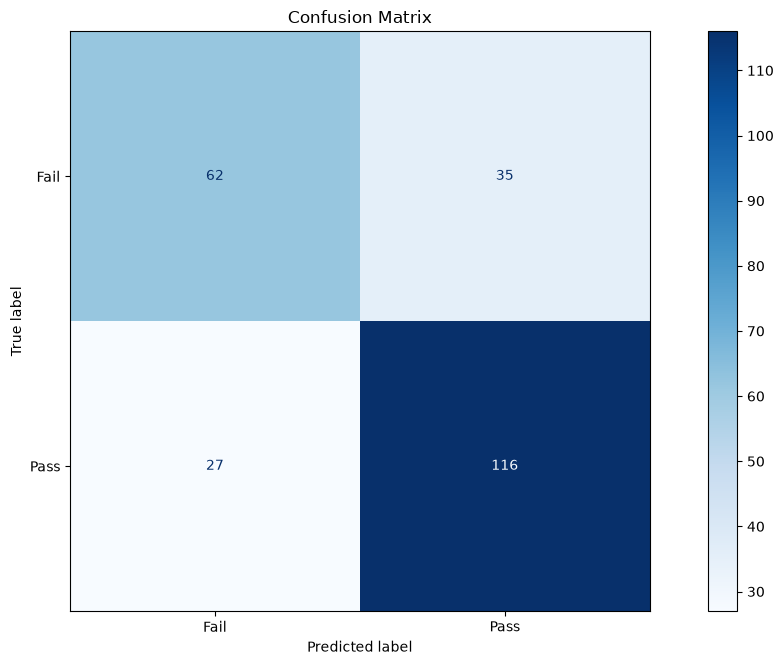

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

### 建立圖表
fig, ax = plt.subplots(figsize=(12, 6.75))

### 繪製 Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, # 實際答案與預測答案
    labels=[0, 1], # 指定類別順序
    display_labels=["Fail", "Pass"], # 顯示類別名稱
    cmap="Blues", # 藍色色階
    values_format="d", # 顯示整數
    ax=ax
)

### 設定圖表
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

ROC Curve

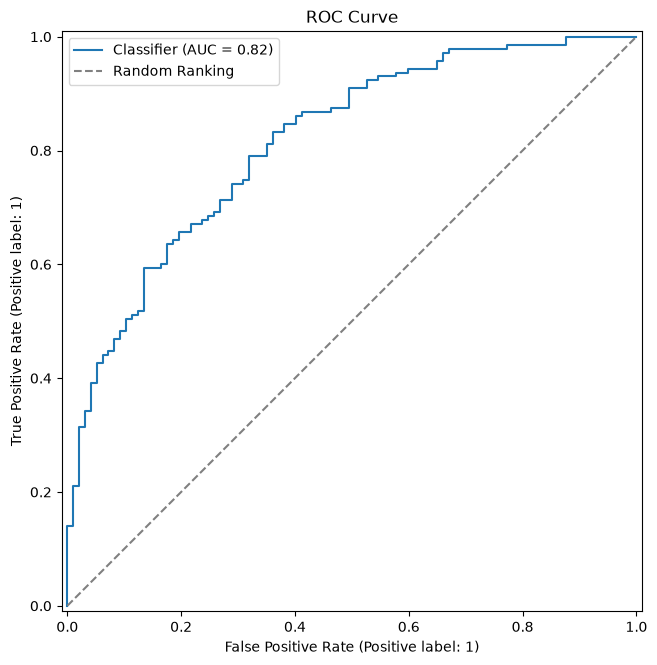

In [18]:
from sklearn.metrics import RocCurveDisplay

### 建立圖表
fig, ax = plt.subplots(figsize=(12, 6.75))

### 繪製 ROC Curve
RocCurveDisplay.from_predictions(
    y_test, y_score, # 實際答案與預測機率
    ax=ax
)

### 繪製隨機排序參考線
ax.plot(
    [0, 1], [0, 1],
    "--", color="gray",
    label="Random Ranking"
)

### 設定圖表
ax.legend()
plt.title("ROC Curve")
plt.tight_layout()
plt.show()